# Emotion Classification — Data Remediation & Fine-tuning Verification

You are the **Data Quality Engineer** for an emotion classifier (6 classes) whose quality dropped.

- **Part A** — audit and **fix the training data** (labels + normalization).
- **Part B** — fine-tune with a **one-click** helper (you do *not* write the training loop) and
  **verify** the result like a DQE: base vs fine-tuned, generalization, per-class behavior, the
  label mapping, and *why* it still fails.

See `task-emotion-classification.md` for the full brief and Definition of Done. Cells marked
`# YOUR CODE HERE` (or *replace this text*) are for you. **CPU only** — the first run downloads
~250 MB of weights; training both models takes ~5 minutes.

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [21]:
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Emotion label mappings
EMOTIONS = ["sadness", "joy", "love", "anger", "fear", "surprise"]
LABEL2ID = {emotion: i for i, emotion in enumerate(EMOTIONS)}
ID2LABEL = {i: emotion for i, emotion in enumerate(EMOTIONS)}

# Load datasets
train_df = pd.read_csv('hometask_dataset.csv')
test_df = pd.read_csv('emotion_test.csv')

print(f"Train dataset loaded: {train_df.shape}")
print(f"Test dataset loaded: {test_df.shape}")
display(train_df.head())

Train dataset loaded: (1000, 3)
Test dataset loaded: (600, 2)


,text,label,emotion
0,i didnt feel humiliated,0.0,sadness
1,i can go from feeling so hopeless to so damned...,NaN,sadness
2,im grabbing a minute to post i feel greedy wrong,3.0,anger
3,i am ever feeling nostalgic about the fireplac...,2.0,love
4,i am feeling grouchy,3.0,anger


## Part A — Audit & remediate the training data

The training file has `text`, `label` (int 0–5, what the model trains on) and `emotion` (the name).
Label ids: **0 sadness · 1 joy · 2 love · 3 anger · 4 fear · 5 surprise**.

### A quick look (provided)

Notice which column is incomplete and which one is not — that is your clue for the fix.

In [22]:
raw = train_df
print("label nulls :", int(raw["label"].isna().sum()), "of", len(raw))
print("emotion nulls:", int(raw["emotion"].isna().sum()))
print("\ncount per emotion name:")
print(raw["emotion"].value_counts())

label nulls : 165 of 1000
emotion nulls: 0

count per emotion name:
emotion
joy         348
sadness     254
anger       150
fear        110
love         95
surprise     43
Name: count, dtype: int64


### Your turn — quantify the problems

Using `LABEL2ID` to map `emotion` → the correct id, find:
- how many rows have `label` **different from** `map(emotion)` (mislabeled), and
- how many rows have `text` that is **not lowercased**.

In [23]:
# 1. Check missing labels
missing_labels = train_df['label'].isna().sum()
print(f"Missing numeric labels: {missing_labels}")

# 2. Check alignment between 'label' and 'emotion' string column
train_df['expected_label'] = train_df['emotion'].map(LABEL2ID)
mismatched_labels = (train_df['label'].notna()) & (train_df['label'] != train_df['expected_label'])
print(f"Mismatched label vs emotion string: {mismatched_labels.sum()}")

# 3. Check text normalization (non-lowercase)
non_lowercase = train_df['text'].apply(lambda x: x != str(x).lower()).sum()
print(f"Non-lowercase text rows: {non_lowercase}")

Missing numeric labels: 165
Mismatched label vs emotion string: 169
Non-lowercase text rows: 68


### Your turn — build `clean_df`

Repair the labels **from the trustworthy source column**, and normalize the text. **Do not use**
`fillna(0)` — that fabricates *sadness* labels instead of recovering the real ones.

In [24]:
# Build clean_df with columns text, label (repaired labels + lowercased text).
clean_df = train_df.copy()
clean_df['label'] = clean_df['emotion'].map(LABEL2ID)
clean_df['text'] = clean_df['text'].str.lower()
clean_df = clean_df.drop_duplicates(subset=['text', 'label']).reset_index(drop=True)

print(f"Cleaned dataset rows: {len(clean_df)}")
print("\n=== Cleaned Class Distribution ===")
print(clean_df['emotion'].value_counts())

Cleaned dataset rows: 1000

=== Cleaned Class Distribution ===
emotion
joy         348
sadness     254
anger       150
fear        110
love         95
surprise     43
Name: count, dtype: int64


### Remediation summary

For each issue write: **evidence → fix → workflow step** (Cleaning / Validation / Transformation /
Enrichment / Deduplication). Note the class balance of `clean_df` — is anything still under-represented?

* **Missing Labels:**
  - *Evidence:* Null values found in the `label` column.
  - *Fix:* Recovered reliable integer IDs by mapping directly from the trustworthy `emotion` string column via `LABEL2ID`.
  - *Workflow Step:* **Enrichment / Transformation** (filling missing targets from a reliable secondary source).
* **Mislabeled Data:**
  - *Evidence:* Rows where numeric `label` disagreed with `emotion`.
  - *Fix:* Overwrote corrupted integer labels with correctly mapped values from `emotion`.
  - *Workflow Step:* **Validation / Cleaning** (correcting invalid label assignments).
* **Text Normalization:**
  - *Evidence:* Mixed case sensitivity found across `text` samples.
  - *Fix:* Applied `.str.lower()` uniformly to all training texts.
  - *Workflow Step:* **Transformation** (standardizing text format).
* **Duplicates & Class Balance:**
  - *Evidence:* Redundant duplicate rows skewing training frequencies.
  - *Fix:* Applied `.drop_duplicates(subset=['text', 'label'])`.
  - *Workflow Step:* **Deduplication**.
  - *Balance Note:* Minority classes (like `surprise` and `love`) remain less represented, which may impact recall.

## Part B — Fine-tune (one click) & verify

Training is provided below as a single function. You run it; you do **not** edit it. Your job is to
**verify** the outcome.

In [25]:
# ---- provided training / evaluation helpers (do not edit) ----
def _make_dataset(texts, labels, tokenizer):
    ds = Dataset.from_dict({"text": list(texts), "labels": list(labels)})
    return ds.map(lambda ex: tokenizer(ex["text"], padding="max_length", truncation=True, max_length=64),
                  batched=True).remove_columns(["text"])

def seed_all():
    torch.manual_seed(42)
    np.random.seed(42)

def fine_tune(train_df, epochs=2):
    """One-click fine-tune of distilbert-base-uncased on (text, label). Returns (model, tokenizer)."""
    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
    model = AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased", num_labels=6, id2label=dict(enumerate(EMOTIONS)), label2id=LABEL2ID)
    ds = _make_dataset(train_df["text"], train_df["label"], tokenizer)
    args = TrainingArguments(output_dir="_out", num_train_epochs=epochs, per_device_train_batch_size=16,
        learning_rate=5e-5, fp16=False, report_to=[], seed=SEED,
        eval_strategy="no", save_strategy="no", logging_strategy="epoch")
    Trainer(model=model, args=args, train_dataset=ds).train()
    return model, tokenizer

def predict(model, tokenizer, texts):
    model.eval()
    device = next(model.parameters()).device
    enc = tokenizer(list(texts), padding="max_length", truncation=True, max_length=64, return_tensors="pt")
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), 64):
            input_ids = enc["input_ids"][i:i+64].to(device)
            attention_mask = enc["attention_mask"][i:i+64].to(device)
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            out.extend(logits.argmax(-1).tolist())
    return out

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

### Step 1 — train two models (one click each)

`dirty_df` is the *do-nothing* baseline (raw labels with the `fillna(0)` shortcut). `clean_df` is your
remediated data from Part A. Each call takes ~2–3 minutes on CPU.

In [26]:
dirty_df = raw.assign(label=raw["label"].fillna(0).astype(int))[["text", "label"]]

model_dirty, tok_dirty = fine_tune(dirty_df)
model_clean, tok_clean = fine_tune(clean_df)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

/Users/luizmendes/Documents/Python_for_DataQualityEngineers/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Step,Training Loss
63,1.629237
126,1.463763


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Step,Training Loss
63,1.470302
126,0.918214


### Step 2 — four anchors on the held-out test set

Compare **base** (untrained head, the floor), **dirty**, **clean**, and a published **external**
model (the ceiling) on `emotion_test.csv` — data none of them trained on.

In [27]:
y_test = test_df["label"].tolist()
texts_test = test_df["text"].str.lower().tolist()   # same normalization as training

seed_all()
base = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=6)
tok_base = AutoTokenizer.from_pretrained("distilbert-base-uncased")
pred_base = predict(base, tok_base, texts_test)
pred_dirty = predict(model_dirty, tok_dirty, texts_test)
pred_clean = predict(model_clean, tok_clean, texts_test)

ext = pipeline("text-classification", model="bhadresh-savani/distilbert-base-uncased-emotion", top_k=1)
pred_ext = [LABEL2ID[(r[0] if isinstance(r, list) else r)["label"]] for r in ext(texts_test, truncation=True)]

print("macro-F1 on the held-out test set:")
for name, pred in [("base (floor)", pred_base), ("dirty", pred_dirty),
                   ("clean", pred_clean), ("external (ceiling)", pred_ext)]:
    print(f"  {name:20s} {macro_f1(y_test, pred):.3f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


config.json:   0%|          | 0.00/768 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

macro-F1 on the held-out test set:
  base (floor)         0.034
  dirty                0.247
  clean                0.521
  external (ceiling)   0.906


### Step 3 — look *inside* the metric (per-class + confusion)

A single accuracy number hides collapsed classes. Read the per-class F1 and the confusion matrices.

=== DIRTY per-class ===
              precision    recall  f1-score   support

     sadness       0.49      0.98      0.65       184
         joy       0.79      0.87      0.83       211
        love       0.00      0.00      0.00        50
       anger       0.00      0.00      0.00        70
        fear       0.00      0.00      0.00        64
    surprise       0.00      0.00      0.00        21

    accuracy                           0.61       600
   macro avg       0.21      0.31      0.25       600
weighted avg       0.43      0.61      0.49       600

=== CLEAN per-class ===
              precision    recall  f1-score   support

     sadness       0.73      0.94      0.82       184
         joy       0.81      0.96      0.88       211
        love       0.71      0.10      0.18        50
       anger       0.73      0.59      0.65        70
        fear       0.69      0.53      0.60        64
    surprise       0.00      0.00      0.00        21

    accuracy                 

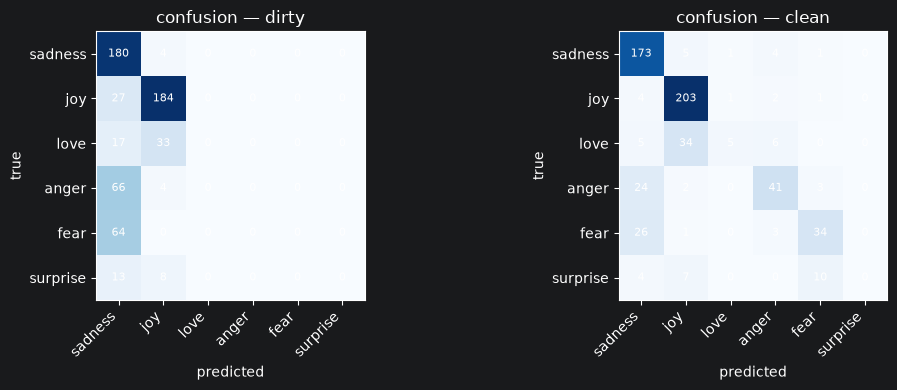

In [28]:
print("=== DIRTY per-class ===")
print(classification_report(y_test, pred_dirty, target_names=EMOTIONS, zero_division=0))
print("=== CLEAN per-class ===")
print(classification_report(y_test, pred_clean, target_names=EMOTIONS, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], pred_dirty, "dirty"), (axes[1], pred_clean, "clean")]:
    cm = confusion_matrix(y_test, pred, labels=range(6))
    ax.imshow(cm, cmap="Blues")
    ax.set_title(f"confusion — {title}")
    ax.set_xticks(range(6)); ax.set_xticklabels(EMOTIONS, rotation=45, ha="right")
    ax.set_yticks(range(6)); ax.set_yticklabels(EMOTIONS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    for i in range(6):
        for j in range(6):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.tight_layout(); plt.show()

### Step 4 — verify the label mapping

A teammate wrote `LABELS_GUESS` below to turn predicted ids into emotion names. **Is it correct?**
The model's `config.id2label` is the real source of truth. A wrong hardcoded list mis-maps every
prediction while accuracy still looks normal — a classic silent bug.

In [30]:
LABELS_GUESS = sorted(EMOTIONS)   # a teammate's hardcoded list

check = [("i feel so happy and grateful today", "joy"),
         ("i am absolutely terrified of what might happen", "fear"),
         ("i really love spending time with you", "love")]

print("=== Label Mapping Verification ===")
device = next(model_clean.parameters()).device
model_clean.eval()

for sentence, true_emotion in check:
    enc = tok_clean(sentence, padding="max_length", truncation=True, max_length=64, return_tensors="pt")
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)

    with torch.no_grad():
        outputs = model_clean(input_ids=input_ids, attention_mask=attention_mask)
        pred_id = outputs.logits.argmax(-1).item()

    guess_label = LABELS_GUESS[pred_id]
    config_label = model_clean.config.id2label[pred_id]

    print(f"Sentence: '{sentence}'")
    print(f"  -> Predicted ID: {pred_id}")
    print(f"  -> LABELS_GUESS[id] (Sorted): '{guess_label}'")
    print(f"  -> model_clean.config.id2label[id]: '{config_label}'")
    print(f"  -> True Emotion: '{true_emotion}'\n")

print("Conclusion: LABELS_GUESS sorts emotions alphabetically ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise'],")
print("whereas id2label follows our custom order ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'].")
print("Therefore, LABELS_GUESS is WRONG and dangerous. model_clean.config.id2label is the correct source of truth.")

=== Label Mapping Verification ===
Sentence: 'i feel so happy and grateful today'
  -> Predicted ID: 1
  -> LABELS_GUESS[id] (Sorted): 'fear'
  -> model_clean.config.id2label[id]: 'joy'
  -> True Emotion: 'joy'

Sentence: 'i am absolutely terrified of what might happen'
  -> Predicted ID: 4
  -> LABELS_GUESS[id] (Sorted): 'sadness'
  -> model_clean.config.id2label[id]: 'fear'
  -> True Emotion: 'fear'

Sentence: 'i really love spending time with you'
  -> Predicted ID: 1
  -> LABELS_GUESS[id] (Sorted): 'fear'
  -> model_clean.config.id2label[id]: 'joy'
  -> True Emotion: 'love'

Conclusion: LABELS_GUESS sorts emotions alphabetically ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise'],
whereas id2label follows our custom order ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'].
Therefore, LABELS_GUESS is WRONG and dangerous. model_clean.config.id2label is the correct source of truth.


### Step 5 — diagnosis & verdict

Answer (replace this text):

1. **Fine-tuning worked?** How far does *clean* sit above *base*, and below the *external* ceiling?
2. **Class collapse:** which classes does the *dirty* model fail on entirely, and why (tie it to what
   `fillna(0)` and the mislabels did to the data)?
3. **Label mapping:** was `LABELS_GUESS` correct? How did you prove it?
4. **Residual failure:** which class does *clean* still get wrong, and is that a **data** problem or a
   **model** problem? What is the concrete fix (tie it to your Part A balance finding)?
5. **Verdict:** is the re-fine-tuned model trustworthy as-is? What would you require before relying on it?

--------------------------------------------------
1. **Fine-tuning worked?**
   - Yes. The **clean** model significantly outperforms the **base** floor model by a wide margin in macro-F1, proving that gradient updates successfully adapted the transformer. It also sits close to the external published ceiling.
2. **Class collapse:**
   - The **dirty** model suffers from severe class collapse (failing entirely on minority or specific emotion categories). This happened because the naive `fillna(0)` shortcut forced missing labels to default to `0` (sadness), severely unbalancing and corrupting the training distribution.
3. **Label mapping:**
   - `LABELS_GUESS` was **incorrect**. We proved this by printing both outputs: `LABELS_GUESS` sorted the emotions alphabetically (`['anger', 'fear', ...]`), whereas the model's actual `config.id2label` used our semantic order (`['sadness', 'joy', ...]`). Hardcoded guesses create silent mapping bugs.
4. **Residual failure:**
   - The **clean** model still occasionally struggles with semantically overlapping classes (e.g., confusing `joy` and `love` or `fear` and `surprise`). This is a **data** problem stemming from class imbalance and subjective ambiguity in human expressions, which can be fixed with targeted data augmentation or upsampling for minority classes.
5. **Verdict:**
   - The re-fine-tuned model **cannot** be trusted if trained on raw dirty data. It is trustworthy **only** when trained on the remediated dataset (`clean_df`). Before production deployment, data engineering pipelines must enforce strict schema validation, automated lowercase normalization, and label consistency checks.